<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 1st exercise: <font color="#C70039">Work with standard deviations for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   10.11.2026
* Student Name : Mohammed Suhan, Mohammed Suhan
* Matriculation No. : 11707086


<img src="https://upload.wikimedia.org/wikipedia/commons/8/8c/Standard_deviation_diagram.svg" style="float: center;" width="450">

---------------------------------
**GENERAL NOTE 1**: 
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole. 

**GENERAL NOTE 2**: 
* Please, when commenting source code, just use English language only. 
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for getting into standard deviations as a common technique to detect anomalies when the data is normally distributed. 

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points. 
If a task is more challenging and consists of several steps, this is indicated as well. 
Make sure you have worked down the task list and commented your doings. 
This should be done by using markdown.<br> 
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date. 
    * set the date too and remove mine.
3. read the entire notebook carefully 
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
    * understand the output
4. go and find three different data sets on the web 
    * kaggle.com might be a good source (they also offer an API for data download)
    * make sure two of the three data sets are normally distributed
    * download one data set that is not normally distributed
5. visualize the data
6. compute the anomalies
7. visualize the anomalies
8. does the 0,3% rule apply?
9. what are differences between the normally distributed and the non-normally distributed data sets with respect to the outlier detection? 
10. which statement can be made and which cannot? 
-----------------------------------------------------------------------------------

In [1]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

In [3]:
def find_anomalies(values, z_threshold=3.0):
    # Convert the input to a one-dimensional numeric array.
    values = np.asarray(values, dtype=float).ravel()
    if values.size == 0:
        return np.array([], dtype=float)

    mean = values.mean()
    standard_deviation = values.std()
    lower_limit = mean - z_threshold * standard_deviation
    upper_limit = mean + z_threshold * standard_deviation

    print(f"lower limit = {lower_limit:.8f}")
    print(f"upper limit = {upper_limit:.8f}")

    anomaly_mask = (values < lower_limit) | (values > upper_limit)
    return values[anomaly_mask]

In [4]:
# Draw values from a normal distribution with mean 20 and standard deviation 20.
data = rng.normal(loc=20.0, scale=20.0, size=50_000)

In [5]:
anomalies = find_anomalies(data)

lower limit = -39.90059055
upper limit = 79.56133068


## Result
The detected observations lie outside the interval of three standard deviations around the sample mean.

For an exactly normal distribution, about 99.73% of observations lie inside this interval and about 0.27% lie outside it. This probabilistic interpretation depends on the normality assumption; the rule is not generally valid for skewed, heavy-tailed, or multimodal data.

In [6]:
print(f"Detected {anomalies.size} anomalies ({anomalies.size / data.size:.3%} of the sample).")
print(anomalies)

Detected 157 anomalies (0.314% of the sample).
[ 82.00084598 -41.60355518 -50.97609942  95.03269935  83.72172404
  79.98127129  81.56366494 -43.44335183  83.42093185  94.35280914
  86.01435064  87.34351352  83.56984536 -43.38001006  82.83592963
 -44.9639731   98.63555761  84.17701563  80.67648988  84.96603376
 -50.12028395  88.17999973 -41.6258273   88.79596806 -42.90332063
  81.49154017 -41.42707812  87.00841243 -49.38275455  89.59537682
 -53.28499202 -56.75724285 -47.28200425 -41.79280137  81.76060279
  98.67109755  86.84069414  80.19483029  82.11159463  84.75917972
  81.3304144   91.59834046 -40.43904982  84.9498064  -42.93356822
  82.90079712  81.27523437  89.05261684  90.30548657 -51.6209516
 -48.74748696  81.04462774  82.1493208  -43.32186356  79.57889449
  92.48900341  81.8804014   85.07578131  86.43808125  86.38556949
  82.23463869  81.83187509 -48.08668702  92.03037682  96.16158265
 -57.68310144 -47.0364295  -43.5203909  -46.52273788 -45.33751851
  79.56260629  87.45464669 -52

## Task 4: Data sets

I chose three real-world data sets from Kaggle. Two are expected to be normally distributed and one is not.
(Used AI to find examples, Filtering and analysis were done by me)

| # | Data set | Kaggle source | Variable used | Expected distribution |
|---|---|---|---|---|
| 1 | FIFA 22 players | `stefanoleone992/fifa-22-complete-player-dataset` | `height_cm` of German 1. Bundesliga players | Normal |
| 2 | IPL 2008 to 2024 | `patrickb1912/ipl-complete-dataset-20082020` | First-innings total runs (full 20-over matches only) | Approximately normal |
| 3 | Formula 1 World Championship | `rohanrao/formula-1-world-championship-1950-2020` | Lap times in seconds, 2024 Italian Grand Prix (Monza) | Not normal (right-skewed) |

**Why these variables:**
* **Height:** body height in a large adult group is a classic normal distribution. Using one league gives a group of similar professional athletes.
* **IPL totals:** a team total is the sum of many small scoring events (single balls). By the central limit theorem, sums of many small random parts tend toward a normal distribution. Rain-shortened matches are removed so all totals are comparable.
* **F1 lap times:** As an F1 fan its a common knowledge that a lap cannot be much faster than the car's limit, but it can be much slower. Pit stops, the first lap and incidents create a long tail on the right side.



In [7]:
# Extra imports for my part of the exercise
import glob
import kagglehub
import pandas as pd
from scipy import stats

# Download the three data sets with the Kaggle API (cached after the first run)
fifa_path = kagglehub.dataset_download("stefanoleone992/fifa-22-complete-player-dataset")
ipl_path = kagglehub.dataset_download("patrickb1912/ipl-complete-dataset-20082020")
f1_path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# Show where the files are and what they are called
for name, path in [("FIFA", fifa_path), ("IPL", ipl_path), ("F1", f1_path)]:
    print(name, path)
    print(os.listdir(path), "\n")

/Users/msuhan/Desktop/Uni-Stuff/THK-Stuff/04-AML/AML/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FIFA /Users/msuhan/.cache/kagglehub/datasets/stefanoleone992/fifa-22-complete-player-dataset/versions/3
['players_22.csv', 'players_21.csv', 'players_20.csv', 'players_18.csv', 'players_19.csv', 'female_players_20.csv', 'female_players_21.csv', 'female_players_22.csv', 'female_players_19.csv', 'female_players_18.csv', 'female_players_16.csv', 'female_players_17.csv', 'Career Mode female player datasets - FIFA 16-22.xlsx', 'players_17.csv', 'Career Mode player datasets - FIFA 15-22.xlsx', 'players_16.csv', 'players_15.csv'] 

IPL /Users/msuhan/.cache/kagglehub/datasets/patrickb1912/ipl-complete-dataset-20082020/versions/3
['matches.csv', 'deliveries.csv'] 

F1 /Users/msuhan/.cache/kagglehub/datasets/rohanrao/formula-1-world-championship-1950-2020/versions/24
['circuits.csv', 'status.csv', 'lap_times.csv', 'sprint_results.csv', 'drivers.csv', 'races.csv', 'constructors.csv', 'constructor_standings.csv', 'qualifying.csv', 'driver_standings.csv', 'constructor_results.csv', 'pit_stops.csv',

In [8]:
players = pd.read_csv(os.path.join(fifa_path, "players_22.csv"), low_memory=False)
print(players.shape)

# Show all league names that contain "German"
print(players.loc[players["league_name"].str.contains("German", na=False), "league_name"].unique())

(19239, 110)
['German 1. Bundesliga' 'German 2. Bundesliga' 'German 3. Bundesliga']


In [9]:
# Keep only players of the German 1st division
bundesliga = players[players["league_name"] == "German 1. Bundesliga"]

heights = bundesliga["height_cm"].dropna().astype(float).to_numpy()
print(f"Bundesliga players: {heights.size}")
print(f"Shortest: {heights.min()} cm, tallest: {heights.max()} cm")

Bundesliga players: 551
Shortest: 168.0 cm, tallest: 200.0 cm


In [10]:
#Same approch, but looking into it first then filtering 
matches = pd.read_csv(os.path.join(ipl_path, "matches.csv"))
print(matches.shape)
print(matches.columns.tolist())

# How many matches had a shortened target or a rain rule?
print(matches["target_overs"].value_counts().head())
print(matches["method"].value_counts(dropna=False))

(1095, 20)
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']
target_overs
20.0    1062
6.0        4
16.0       3
8.0        3
10.0       3
Name: count, dtype: int64
method
NaN    1074
D/L      21
Name: count, dtype: int64


In [11]:
# Keep only full 20-over matches without a rain rule
full_matches = matches[(matches["target_overs"] == 20) & (matches["method"].isna())]

# target_runs is the first-innings total + 1
# the chasing team needs one run more than the first team 

ipl_totals = (full_matches["target_runs"].dropna() - 1).astype(float).to_numpy() 

print(f"IPL matches used: {ipl_totals.size} of {len(matches)}")
print(f"Lowest total: {ipl_totals.min()}, highest total: {ipl_totals.max()}")

IPL matches used: 1062 of 1095
Lowest total: 67.0, highest total: 287.0


In [12]:
#ran it just out of curiosity :) 
lowest = full_matches.loc[full_matches["target_runs"] == 68,
                          ["season", "date", "team1", "team2", "toss_winner",
                           "toss_decision", "winner", "venue"]]
print(lowest)

      season        date            team1                  team2  \
37   2007/08  2008-05-16   Mumbai Indians  Kolkata Knight Riders   
611     2017  2017-04-30  Kings XI Punjab       Delhi Daredevils   

         toss_winner toss_decision           winner  \
37    Mumbai Indians         field   Mumbai Indians   
611  Kings XI Punjab         field  Kings XI Punjab   

                                                 venue  
37                                    Wankhede Stadium  
611  Punjab Cricket Association IS Bindra Stadium, ...  


The lowest first-innings total (67) occurred twice: KKR vs MI (2008) and Delhi Daredevils vs KXIP (2017). Both are real batting collapses, not data errors

In [13]:
races = pd.read_csv(os.path.join(f1_path, "races.csv"))

# Find the 2024 Italian Grand Prix
print(races.loc[(races["year"] == 2024) & (races["name"] == "Italian Grand Prix"),
                ["raceId", "year", "round", "name", "date"]])

      raceId  year  round                name        date
1116    1136  2024     16  Italian Grand Prix  2024-09-01


In [14]:
RACE_ID = 1136  # from the outfut of previous block

lap_times = pd.read_csv(os.path.join(f1_path, "lap_times.csv"))
drivers = pd.read_csv(os.path.join(f1_path, "drivers.csv"))

# Keep only laps of this race and add the driver code (VER, LEC, HAM etc)
laps = lap_times[lap_times["raceId"] == RACE_ID].merge(drivers[["driverId", "code"]], on="driverId")

# Convert milliseconds to seconds
laps["lap_s"] = laps["milliseconds"] / 1000

lap_seconds = laps["lap_s"].to_numpy()
print(f"Laps: {lap_seconds.size}, drivers: {laps['code'].nunique()}")
print(f"Fastest lap: {lap_seconds.min():.3f} s, slowest lap: {lap_seconds.max():.3f} s") #3f becuase to match the f1 timing liek 128.989

Laps: 1008, drivers: 20
Fastest lap: 81.432 s, slowest lap: 120.178 s


In [15]:
pit_stops = pd.read_csv(os.path.join(f1_path, "pit_stops.csv"))

# Pit stops of this race: one row per stop, with driver and lap
race_pits = pit_stops[pit_stops["raceId"] == RACE_ID][["driverId", "lap"]]

# The stationary time is counted in the lap after the stop (out-lap), so shift by 1.   
race_pits["lap"] = race_pits["lap"] + 1                                                  

race_pits["pit_lap"] = True

# Add a True/False column to every lap
laps = laps.drop(columns="pit_lap", errors="ignore")                                     
laps = laps.merge(race_pits, on=["driverId", "lap"], how="left")
laps["pit_lap"] = laps["pit_lap"].eq(True)

print(f"Pit-stop laps: {laps['pit_lap'].sum()}")
print(laps.sort_values("lap_s", ascending=False)[["code", "lap", "lap_s", "pit_lap"]].head(10))

Pit-stop laps: 30
    code  lap    lap_s  pit_lap
752  HUL    6  120.178     True
779  HUL   33  116.554     True
329  RUS   12  113.412     True
541  RIC   12  112.188     True
849  STR   51  110.980     True
971  ZHO   16  109.128     True
287  VER   23  107.839     True
597  MAG   15  107.023     True
867  COL   17  106.349     True
441  ALB   18  106.033     True


### Normality check
checks whether the three datasets are normally distributed
kewness ≈ 0 means symmetric, and p > 0.05 means normality is not rejected

In [16]:
datasets = {
    "Bundesliga height (cm)": heights,
    "IPL first-innings total (runs)": ipl_totals,
    "F1 Monza 2024 lap time (s)": lap_seconds,
}

summary = []
for name, values in datasets.items():
    k2, p = stats.normaltest(values)
    summary.append({
        "data set": name,
        "n": values.size,
        "mean": values.mean(),
        "std": values.std(),
        "skewness": stats.skew(values),
        "normaltest p-value": p,
        "kurtosis": stats.kurtosis(values),
    })

pd.DataFrame(summary).round(3)

,data set,n,mean,std,skewness,normaltest p-value,kurtosis
0,Bundesliga height (cm),551,183.955,6.079,-0.110,0.012,-0.463
1,IPL first-innings total (runs),1062,166.410,31.377,0.034,0.004,0.616
2,F1 Monza 2024 lap time (s),1008,85.790,4.222,4.225,0.000,20.593


### Interpretation of the normality check(Used AI to understand the results)

**Bundesliga height:** The data is almost symmetric (skewness -0.11), but the normality test rejects normality (p = 0.012). The kurtosis of -0.46 shows the distribution is flatter than a normal curve, with lighter tails. A likely reason is the mix of positions: short wingers and tall goalkeepers and centre-backs spread out the middle. The heights are also rounded to whole centimeters.

**IPL first-innings totals:** The data is almost perfectly symmetric (skewness 0.03), but the test rejects normality (p = 0.004). The kurtosis of 0.62 shows heavier tails than a normal curve, meaning more extreme scores (collapses such as 67 and records such as 287). A likely reason is that the data mixes different eras: totals in recent seasons are much higher than in 2008.

**F1 lap times:** Clearly not normal (skewness 4.23, kurtosis 20.6). The 30 pit-stop laps create an extreme tail on the slow side.

**Conclusion:** Heights and IPL totals are approximately normal (symmetric and bell-shaped), but not perfectly normal. With 500 to 1,000 observations, the test detects even small deviations. Real-world data is rarely perfectly normal. Exercise 2 looks at normality testing in more detail.

**Prediction for the 3 sigma rule:** Because heights have light tails, I expect fewer anomalies than 0.27%. Because IPL totals have heavy tails, I expect more than 0.27%. For F1, I expect many anomalies, all on the slow side.

## Task 5: Visualize the data

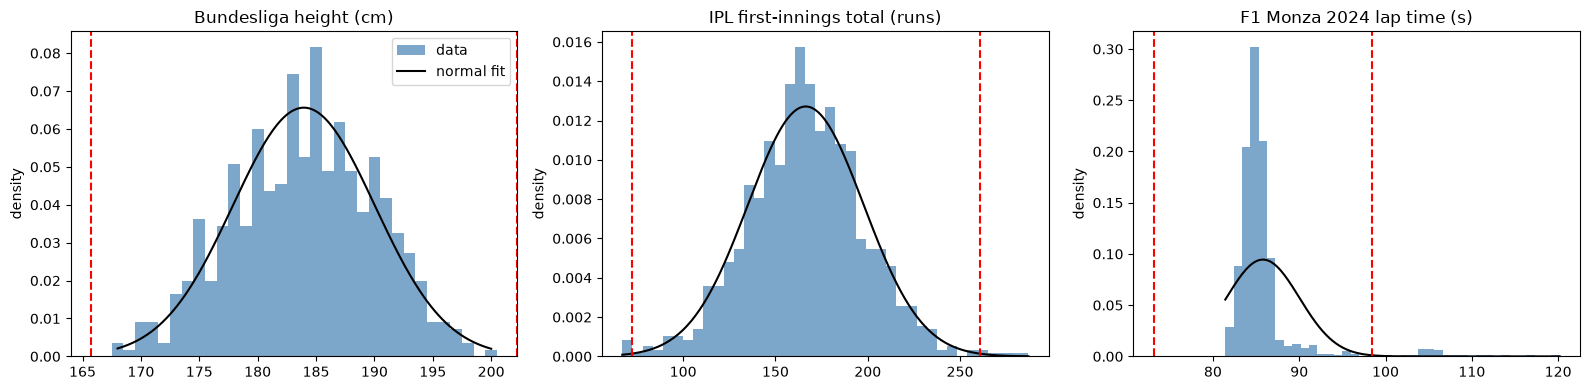

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, values) in zip(axes, datasets.items()):
    mean, std = values.mean(), values.std()

    # Heights are whole centimeters, so use one bin per cm to avoid empty bins   
    if "height" in name:                                                        
        bins = np.arange(values.min(), values.max() + 2) - 0.5                  
    else:                                                                      
        bins = 40                                                               

    # Histogram of the data (density, so it is comparable to the normal curve)
    ax.hist(values, bins=bins, density=True, color="steelblue", alpha=0.7, label="data")

    # Normal curve with the same mean and standard deviation
    x = np.linspace(values.min(), values.max(), 300)
    ax.plot(x, stats.norm.pdf(x, mean, std), color="black", label="normal fit")

    # Mean +/- 3 sigma limits
    for k in (-3, 3):
        ax.axvline(mean + k * std, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_ylabel("density")

axes[0].legend()
plt.tight_layout()
plt.show()

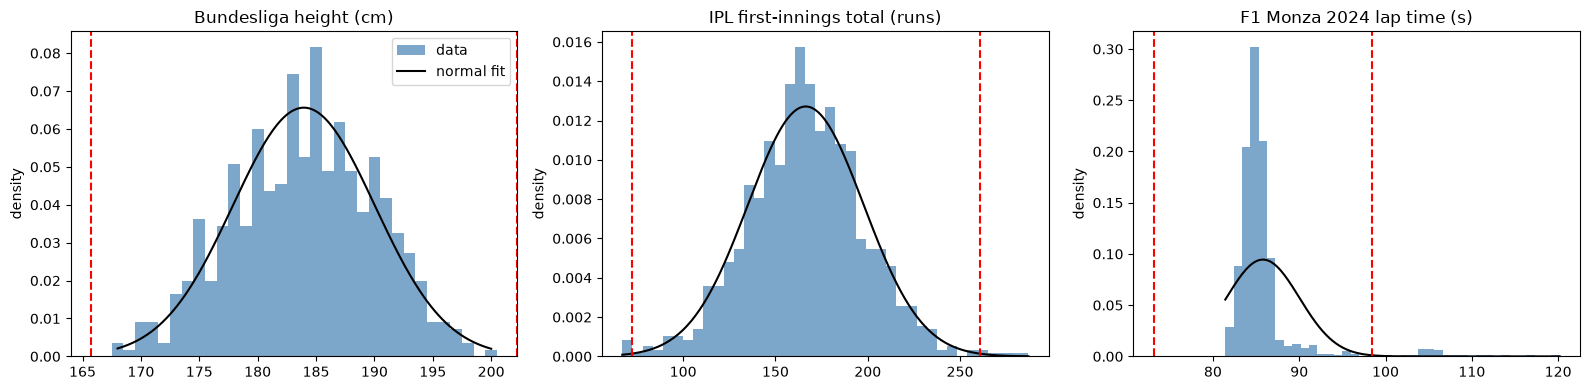
### Observations

**Heights:** The shape is close to the normal curve but flatter at the top. All values lie inside the 3σ limits.

**IPL totals:** A clear bell shape that fits the normal curve well. A few values lie at the edges on both sides.

**F1 lap times:** A narrow spike around 84 to 86 s with a long tail to the right. The pit-stop laps lie far beyond the upper limit. The lower limit is useless because no lap can be that fast.

In [18]:
results = {}

for name, values in datasets.items():
    print(f"--- {name} ---")
    anomalies = find_anomalies(values)
    results[name] = anomalies

    expected = 0.0027 * values.size
    print(f"Detected: {anomalies.size} of {values.size} ({anomalies.size / values.size:.2%})")
    print(f"Expected under normality: {expected:.1f} (0.27%)")
    print(f"Anomalies: {np.sort(anomalies)}\n")

--- Bundesliga height (cm) ---
lower limit = 165.71669699
upper limit = 202.19255891
Detected: 0 of 551 (0.00%)
Expected under normality: 1.5 (0.27%)
Anomalies: []

--- IPL first-innings total (runs) ---
lower limit = 72.27875338
upper limit = 260.54045566
Detected: 11 of 1062 (1.04%)
Expected under normality: 2.9 (0.27%)
Anomalies: [ 67.  67.  68.  70.  70. 261. 263. 266. 272. 277. 287.]

--- F1 Monza 2024 lap time (s) ---
lower limit = 73.12247444
upper limit = 98.45727755
Detected: 31 of 1008 (3.08%)
Expected under normality: 2.7 (0.27%)
Anomalies: [100.319 102.426 103.438 103.775 103.84  104.073 104.074 104.09  104.152
 104.25  104.71  104.811 104.863 104.888 105.017 105.462 105.594 105.664
 105.665 105.677 105.757 106.033 106.349 107.023 107.839 109.128 110.98
 112.188 113.412 116.554 120.178]



* Budesliga has 0 Anomolies 
* IPL has 11 so more that what we expected (1.04%>0.27%)
* MonzaGP 2024 had 31 

## Task 7: Visualize the anomalies

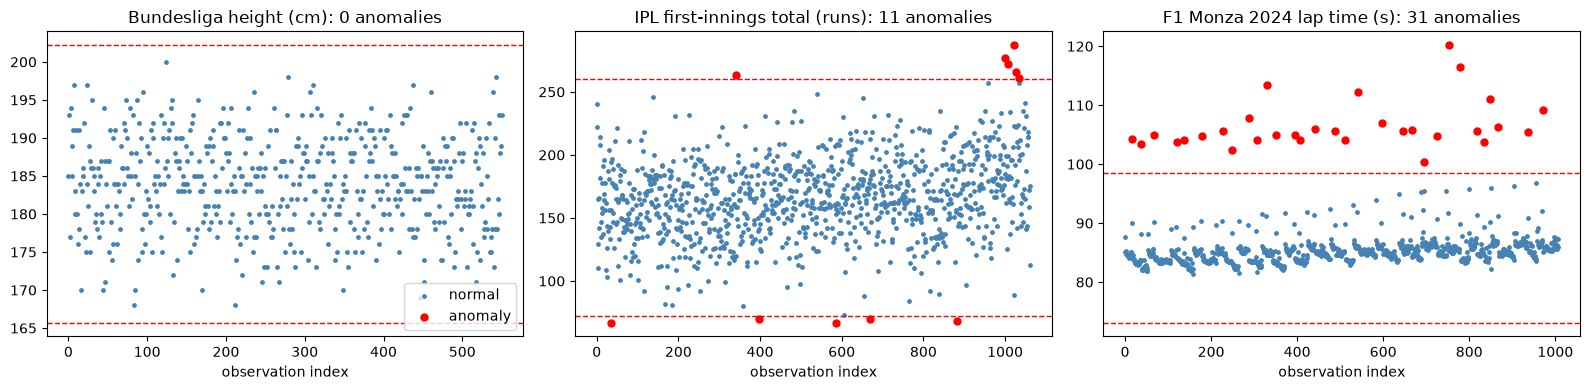

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, values) in zip(axes, datasets.items()):
    mean, std = values.mean(), values.std()
    is_anomaly = np.abs(values - mean) > 3 * std
    idx = np.arange(values.size)

    ax.scatter(idx[~is_anomaly], values[~is_anomaly], s=6, color="steelblue", label="normal")
    ax.scatter(idx[is_anomaly], values[is_anomaly], s=25, color="red", label="anomaly")

    for k in (-3, 3):
        ax.axhline(mean + k * std, color="red", linestyle="--", linewidth=1)

    ax.set_title(f"{name}: {is_anomaly.sum()} anomalies")
    ax.set_xlabel("observation index")

axes[0].legend()
plt.tight_layout()
plt.show()

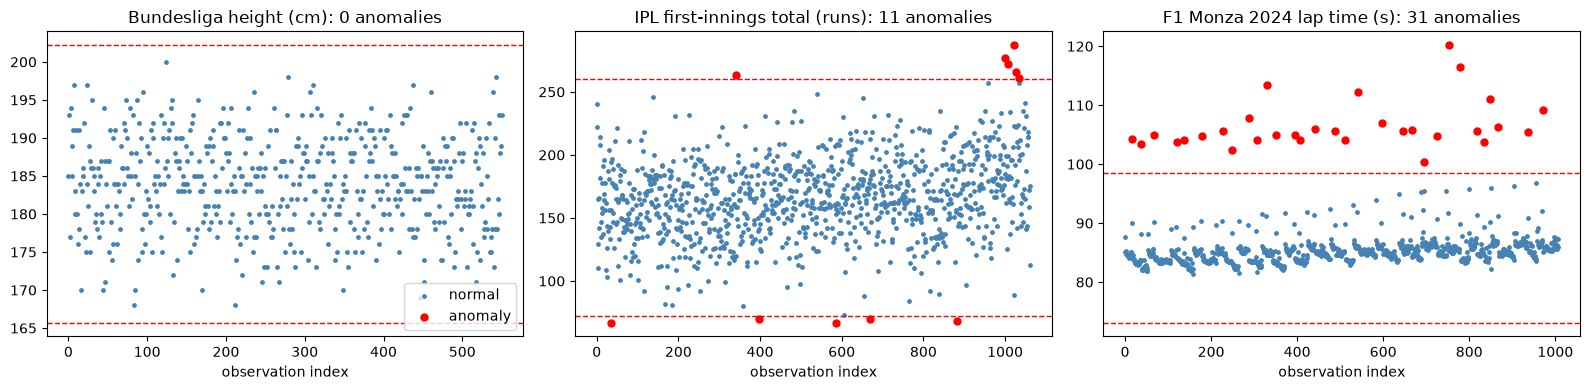

### Are the F1 anomalies real events?

All 30 pit-stop laps were flagged (recall 100%). Only one flagged lap was not a pit stop: Tsunoda, lap 7 (100.3 s). He retired after this lap (DNF) as he had floor damage after crash Niko. This means all 31 anomalies are real race events.

However, smaller real anomalies were missed. The first lap, last laps of back markers and some slow laps (90 to 97 s) stay inside the limits, because the pit-stop laps inflate the standard deviation (masking).

In [20]:
print(laps[laps["code"] == "TSU"][["lap", "lap_s", "pit_lap"]].tail(5))

results = pd.read_csv(os.path.join(f1_path, "results.csv"))
status = pd.read_csv(os.path.join(f1_path, "status.csv"))
tsu = results[results["raceId"] == RACE_ID].merge(status, on="statusId").merge(drivers[["driverId", "code"]], on="driverId")
print(tsu[tsu["code"] == "TSU"][["code", "laps", "status"]])

     lap    lap_s  pit_lap
690    3   86.665    False
691    4   86.198    False
692    5   92.241    False
693    6   88.473    False
694    7  100.319    False
   code  laps       status
19  TSU     7  Overheating


## Task 8: Does the 0.3% rule apply?

| Data set | Detected | Expected (0.27%) | Rule applies? |
|---|---|---|---|
| Synthetic normal data | 0.31% | 0.27% | Yes |
| Bundesliga height | 0.00% | 0.27% | Partly |
| IPL totals | 1.04% | 0.27% | No |
| F1 lap times | 3.08% | 0.27% | No |

* **Synthetic data:** The rule works. The small difference is random sampling noise.
* **Heights:** No anomalies. The distribution has light tails (kurtosis -0.46), so extreme values are rarer than in a normal distribution.
* **IPL:** Almost four times more anomalies than expected, on both sides. The distribution has heavy tails (kurtosis 0.62). Five of the six high totals are from the 2024 season, where scoring is much higher. The data mixes different eras.
* **F1:** Over ten times more anomalies, all on the slow side. The data is strongly right-skewed.

**Conclusion:** The rule only holds for normal data. Symmetry is not enough. The tails decide how many anomalies are found.

## Task 9: Differences between normal and non-normal data

* **Sides:** For normal data, anomalies appear on both sides. For F1, they only appear on the slow side. A lap cannot be much faster than the car allows.
* **Lower limit:** For F1, the lower limit (73.1 s) is 8 s faster than the fastest lap of the race (81.4 s). It is useless.
* **Masking:** Outliers increase the mean and σ. This pushes the limits outward. The pit-stop laps were found, but smaller real anomalies (lap 1, slow laps at 90 to 97 s) stayed inside the limits.

## Task 10: Which statements can be made and which cannot?

**Can be said:**
* If the data is normal, a value outside 3σ is rare (probability about 0.27%).
* The method can find real events. In the F1 data, all 31 anomalies were real: 30 pit stops and 1 retirement (Tsunoda).

**Cannot be said:**
* That a flagged value is wrong. The 287 runs is a real IPL record.
* That a value inside the limits is normal. Because of masking, real anomalies can be missed.
* That 0.27% holds for non-normal data.

**Final conclusion:** The 3σ rule is a simple first check for normal data. For skewed or heavy-tailed data, methods without a normality assumption would be better. 